# SigLIP Zero-Shot vs Frozen-Backbone Linear Probe — Tomato Maturity

**Computer Vision A** · Model: [`google/siglip-base-patch16-224`](https://huggingface.co/google/siglip-base-patch16-224) ([Zhai et al., 2023](https://arxiv.org/abs/2303.15343)) · Data: [Tomato Maturity Detection & Quality Grading](https://www.kaggle.com/datasets/sujaykapadnis/tomato-maturity-detection-and-quality-grading) ([paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC10618421/))

**Question:** How much does a 1,538-parameter linear head on top of a *frozen* SigLIP vision encoder improve over SigLIP's zero-shot (text-prompt) classification of tomato maturity?

**Pipeline**
1. Load data (original images only → no augmentation leakage), stratified train/val/test split
2. Preprocessing hygiene: 224×224, HWC→CHW, normalise to [-1, 1]
3. Load SigLIP, **freeze** the vision encoder, count trainable vs frozen params
4. Extract pooled embeddings once (backbone is frozen → embeddings are fixed)
5. **Before:** zero-shot baseline with text prompts
6. Train `nn.Linear(768, 2)` on the frozen embeddings
7. **After:** compare accuracy, confusion matrices, per-class precision/recall

Runtime: **T4 GPU**.

## 0. Setup

In [ ]:
!pip install -q kagglehub transformers sentencepiece protobuf scikit-learn

import os, json, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoModel, AutoProcessor

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| torch", torch.__version__)
if device == "cpu":
    print("⚠️  No GPU — switch runtime to T4 GPU")

MODEL_ID = "google/siglip-base-patch16-224"
CLASSES = ["Immature", "Mature"]          # label 0, label 1
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

Device: cuda | torch 2.14.1+cu130


## 1. Data — download into Colab and keep **original** images only

The dataset ships each class twice: *original* photos and an *augmented* folder (rotated/flipped/zoomed copies of the same originals). Splitting randomly across both would put near-copies of the same tomato in train **and** test → **data leakage** and an inflated score. We therefore use the originals only, and also drop exact duplicate files by hash.

If `kagglehub` asks for auth: add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's 🔑 **Secrets** sidebar (enable notebook access).

In [ ]:
import kagglehub
try:  # optional: Kaggle credentials from Colab Secrets
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except Exception:
    pass

dataset_path = kagglehub.dataset_download("sujaykapadnis/tomato-maturity-detection-and-quality-grading")
print("Downloaded to:", dataset_path)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for root, dirs, files in os.walk(dataset_path):
    n = sum(Path(f).suffix.lower() in IMG_EXT for f in files)
    if n: print(f"{n:5d} images  {Path(root).relative_to(dataset_path)}")

100%|██████████| 5.08G/5.08G [01:22<00:00, 66.0MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/sujaykapadnis/tomato-maturity-detection-and-quality-grading/versions/1
 2000 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Augment Dataset/Mature
 2000 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Augment Dataset/Immature
  500 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Original Dataset/Mature
  500 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Original Dataset/Immature
 3000 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Quality Grading Dataset/Tomato Quality Grading Dataset/Augment Dataset/Fresh
 3000 images  Tomato Maturity Detection and Quality Grading Dataset/Tomato Quality Gradi

Read the printout above: you should see Maturity (Immature / Mature) and Quality (Fresh / Defect) folders, each with original and augmented versions. The rule below labels by the **class folder name** and skips anything under an `augment*` folder. Quality-grading folders (fresh/defect) are ignored automatically.

In [ ]:
def label_from_folder(name: str):
    n = name.lower()
    if "immature" in n or "unripe" in n: return 0   # check 'immature' BEFORE 'mature'
    if "mature" in n or "ripe" in n:     return 1
    return None

records, seen_hashes, n_dupes = [], set(), 0
for p in sorted(Path(dataset_path).rglob("*")):
    if p.suffix.lower() not in IMG_EXT: continue
    if any("augment" in part.lower() for part in p.parts): continue      # originals only
    label = label_from_folder(p.parent.name)
    if label is None: continue
    h = hashlib.md5(p.read_bytes()).hexdigest()
    if h in seen_hashes: n_dupes += 1; continue                          # exact duplicates
    seen_hashes.add(h)
    records.append({"path": str(p), "label": label, "folder": str(p.parent.relative_to(dataset_path))})

df = pd.DataFrame(records)
print(f"Kept {len(df)} original images, dropped {n_dupes} exact duplicates")
print(df.groupby(["folder", "label"]).size())
assert set(df.label) == {0, 1}, "Expected both classes — check folder names in the printout above"

Kept 931 original images, dropped 69 exact duplicates
folder                                                                                                                                               label
Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Original Dataset/Immature  0        433
Tomato Maturity Detection and Quality Grading Dataset/Tomato Maturity Detection Dataset/Tomato Maturity Detection Dataset/Original Dataset/Mature    1        498
dtype: int64


In [ ]:
# Stratified 70 / 15 / 15 split (same class balance in every split)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(d):4d} images | class counts {d.label.value_counts().sort_index().tolist()}")

train  651 images | class counts [303, 348]
val    140 images | class counts [65, 75]
test   140 images | class counts [65, 75]


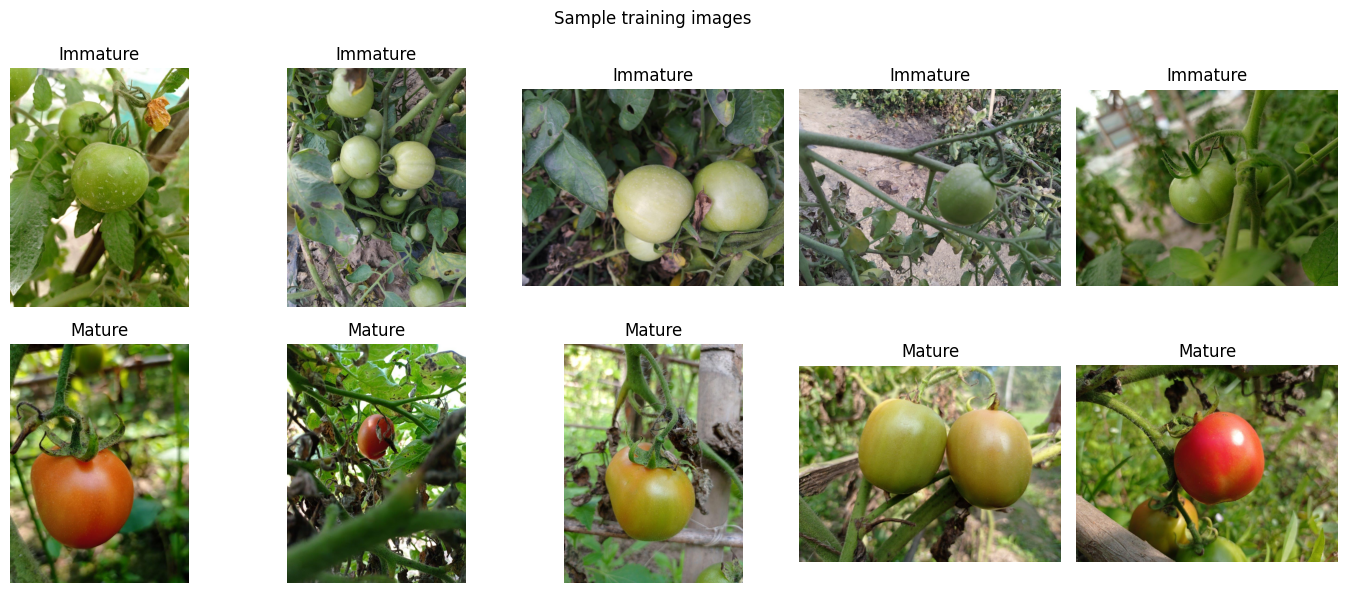

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, label in enumerate([0, 1]):
    for ax, path in zip(axes[row], train_df[train_df.label == label].path.sample(5, random_state=SEED)):
        ax.imshow(Image.open(path).convert("RGB")); ax.set_title(CLASSES[label]); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout()
plt.savefig(OUT / "samples.png", dpi=120); plt.show()

## 2. Preprocessing hygiene — 224×224, HWC→CHW, normalise to [-1, 1]

SigLIP's [preprocessor config](https://huggingface.co/google/siglip-base-patch16-224/blob/main/preprocessor_config.json): resize to **224×224** (bicubic), rescale by 1/255, normalise with **mean = std = (0.5, 0.5, 0.5)** → pixels in **[-1, 1]**. (Not CLIP's ImageNet-style 0.4814… values.)

Why 224: the ViT cuts the image into **16×16-pixel patches** → 224/16 = **14×14 = 196 patch tokens**.

Below we do it **by hand** first, then verify that `AutoProcessor` produces the same tensor.

In [ ]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
print(processor.image_processor)  # shows size, resample, image_mean, image_std

img = Image.open(train_df.path.iloc[0]).convert("RGB")
print("Raw PIL size (W, H):", img.size)

# --- manual pipeline ---
resized = img.resize((224, 224), resample=Image.BICUBIC)
hwc = np.asarray(resized, dtype=np.float32)            # (224, 224, 3)  HWC, 0..255
print("HWC array:", hwc.shape, "range", hwc.min(), "→", hwc.max())
x = hwc / 255.0                                        # 0..1
x = (x - 0.5) / 0.5                                    # -1..1
chw = torch.from_numpy(x).permute(2, 0, 1)             # (3, 224, 224)  CHW
print("CHW tensor:", tuple(chw.shape), f"range {chw.min():.3f} → {chw.max():.3f}")

# --- Hugging Face processor ---
pv = processor(images=img, return_tensors="pt")["pixel_values"]   # (1, 3, 224, 224)  NCHW
print("Processor output:", tuple(pv.shape), f"range {pv.min():.3f} → {pv.max():.3f}")
print(f"Max |manual − processor| = {(chw - pv[0]).abs().max():.4f}  (≈0 → pipelines match)")

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  798kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

SiglipImageProcessor {
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "SiglipImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

Raw PIL size (W, H): (1280, 960)
HWC array: (224, 224, 3) range 0.0 → 255.0
CHW tensor: (3, 224, 224) range -1.000 → 1.000
Processor output: (1, 3, 224, 224) range -1.000 → 1.000
Max |manual − processor| = 0.0078  (≈0 → pipelines match)


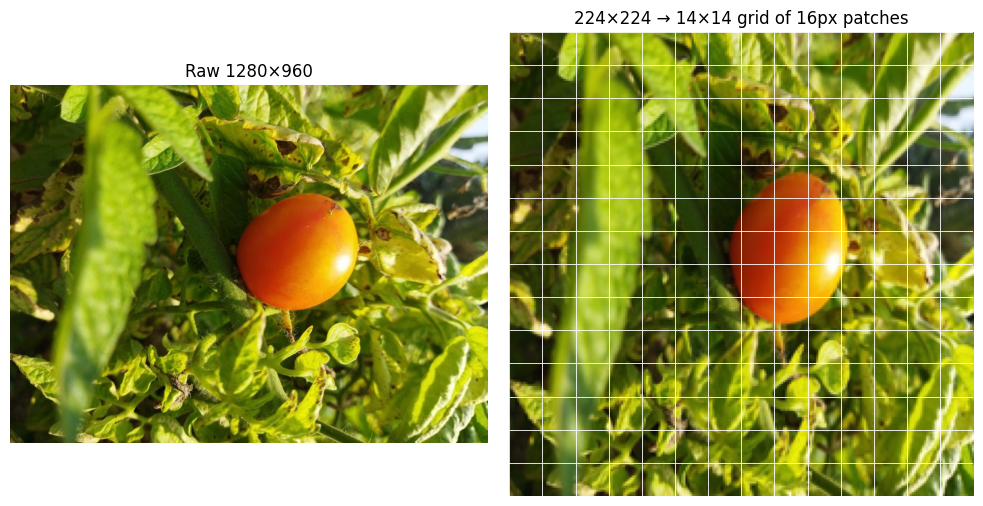

In [ ]:
# Visualise the 14×14 patch grid the ViT actually sees
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img); ax[0].set_title(f"Raw {img.size[0]}×{img.size[1]}"); ax[0].axis("off")
ax[1].imshow(resized); ax[1].set_title("224×224 → 14×14 grid of 16px patches"); ax[1].axis("off")
for k in range(0, 225, 16):
    ax[1].axhline(k - 0.5, color="white", lw=0.6); ax[1].axvline(k - 0.5, color="white", lw=0.6)
plt.tight_layout(); plt.savefig(OUT / "patch_grid.png", dpi=120); plt.show()

## 3. Load SigLIP and **freeze** the vision encoder

SigLIP = image tower (`vision_model`) + text tower (`text_model`). We freeze **both**: the text tower is only used for the zero-shot baseline, the vision tower becomes a fixed feature extractor. The only trainable thing will be the new linear head.

In [ ]:
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()

# Intentional layer freezing (mandatory)
for param in model.vision_model.parameters():
    param.requires_grad = False
for param in model.text_model.parameters():
    param.requires_grad = False

class SigLIPLinearProbe(nn.Module):
    # Frozen SigLIP vision encoder → pooled 768-d embedding → trainable nn.Linear(768, 2)
    def __init__(self, vision_model, num_classes=2):
        super().__init__()
        self.backbone = vision_model                                   # frozen
        self.head = nn.Linear(vision_model.config.hidden_size, num_classes)  # trainable

    def forward(self, pixel_values):
        with torch.no_grad():
            feats = self.backbone(pixel_values=pixel_values).pooler_output  # (B, 768)
        return self.head(feats)                                            # (B, 2)

# Head size comes from the class list: nn.Linear(768, len(CLASSES)) = nn.Linear(768, 2)
probe = SigLIPLinearProbe(model.vision_model, num_classes=len(CLASSES)).to(device)

count = lambda params: sum(p.numel() for p in params)
trainable = count(p for p in probe.parameters() if p.requires_grad)
frozen    = count(p for p in probe.parameters() if not p.requires_grad)
print(f"Hidden size           : {model.vision_model.config.hidden_size}")
print(f"Frozen  (vision enc.) : {frozen:,}")
print(f"Trainable (head)      : {trainable:,}   = 768×{len(CLASSES)} weights + {len(CLASSES)} biases")
print(f"Trainable fraction    : {100 * trainable / (trainable + frozen):.4f}%")

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Hidden size           : 768
Frozen  (vision enc.) : 92,884,224
Trainable (head)      : 1,538   = 768×2 weights + 2 biases
Trainable fraction    : 0.0017%


## 4. Extract the pooled embeddings **once**

Because the backbone is frozen and we use no random augmentation, each image's 768-d `pooler_output` is identical every epoch. So we compute it once and train the head on the cached embeddings. Mathematically the same as running the full `probe` each epoch, ~100× faster. (The cell after verifies this equivalence.)

SigLIP's `pooler_output` comes from its attention-pooling head (MAP head), not a [CLS] token.

In [ ]:
class ImageDS(Dataset):
    def __init__(self, frame): self.paths, self.labels = frame.path.tolist(), frame.label.tolist()
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return Image.open(self.paths[i]).convert("RGB"), self.labels[i]

def collate(batch):
    imgs, labels = zip(*batch)
    return processor(images=list(imgs), return_tensors="pt")["pixel_values"], torch.tensor(labels)

@torch.no_grad()
def embed(frame, bs=64):
    loader = DataLoader(ImageDS(frame), batch_size=bs, collate_fn=collate, num_workers=2)
    feats, labels = [], []
    for pixel_values, y in loader:
        feats.append(model.vision_model(pixel_values=pixel_values.to(device)).pooler_output.cpu())
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)

X_train, y_train = embed(train_df)
X_val,   y_val   = embed(val_df)
X_test,  y_test  = embed(test_df)
print("Embeddings:", tuple(X_train.shape), tuple(X_val.shape), tuple(X_test.shape))

Embeddings: (651, 768) (140, 768) (140, 768)


In [ ]:
# Sanity check: full probe forward on raw pixels == head on cached embeddings
pv_batch, _ = collate([ImageDS(val_df)[i] for i in range(4)])
with torch.no_grad():
    a = probe(pv_batch.to(device)).cpu()
    b = probe.head(X_val[:4].to(device)).cpu()
print("Cache equivalent to full forward:", torch.allclose(a, b, atol=1e-4))

Cache equivalent to full forward: True


## 5. BEFORE — Zero-shot baseline (no training)

Embed a few text prompts per class with the text tower, average them (prompt ensembling, as in [CLIP](https://arxiv.org/abs/2103.00020)), and score each image with SigLIP's own formula:
`logit = cos_sim(image, text) × exp(logit_scale) + logit_bias`. Highest logit wins.

⚠️ SigLIP text **must** be tokenised with `padding="max_length"` — that is how it was trained ([HF docs](https://huggingface.co/docs/transformers/model_doc/siglip)).

Zero-shot  val accuracy: 0.7643
Zero-shot test accuracy: 0.7857


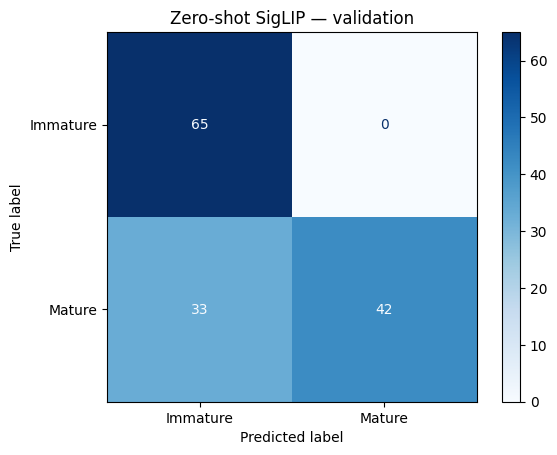

In [ ]:
PROMPTS = {
    0: ["a photo of an unripe green tomato.", "a photo of an immature tomato.", "a photo of a green tomato."],
    1: ["a photo of a ripe red tomato.",      "a photo of a mature tomato.",   "a photo of a red tomato."],
}

@torch.no_grad()
def class_text_embeddings():
    out = []
    for c in range(len(CLASSES)):
        tok = processor(text=PROMPTS[c], padding="max_length", return_tensors="pt").to(device)
        t = F.normalize(model.text_model(input_ids=tok["input_ids"]).pooler_output, dim=-1)
        out.append(F.normalize(t.mean(0), dim=-1))            # average prompts, re-normalise
    return torch.stack(out)                                  # (2, 768)

@torch.no_grad()
def zero_shot_predict(X):English (United States)

    Help
    Privacy
    Terms
    T = class_text_embeddings()
    I = F.normalize(X.to(device), dim=-1)
    logits = I @ T.T * model.logit_scale.exp() + model.logit_bias
    return logits.argmax(-1).cpu()

zs_val_pred, zs_test_pred = zero_shot_predict(X_val), zero_shot_predict(X_test)
print(f"Zero-shot  val accuracy: {accuracy_score(y_val,  zs_val_pred):.4f}")
print(f"Zero-shot test accuracy: {accuracy_score(y_test, zs_test_pred):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_val, zs_val_pred), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Zero-shot SigLIP — validation"); plt.savefig(OUT / "cm_zero_shot_val.png", dpi=120); plt.show()

## 6. Train the linear head on frozen embeddings

Optimiser receives **only** `probe.head.parameters()`. Cross-entropy loss on raw logits. We log train and validation loss every epoch and keep the head from the epoch with the lowest validation loss (early-stopping-style model selection — the test set is never used for choices).

In [ ]:
EPOCHS, LR, BS = 50, 1e-3, 32
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BS, shuffle=True)
optimizer = torch.optim.AdamW(probe.head.parameters(), lr=LR, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val, best_state = float("inf"), None

for epoch in range(EPOCHS):
    probe.head.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = probe.head(xb)          # 1. forward
        loss = loss_fn(logits, yb)       # 2. loss
        optimizer.zero_grad()            # 3. clear old grads
        loss.backward()                  # 4. backprop (only reaches the head)
        optimizer.step()                 # 5. update head weights

    probe.head.eval()
    with torch.no_grad():
        for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]:
            logits = probe.head(X.to(device))
            history[f"{split}_loss"].append(loss_fn(logits, y.to(device)).item())
            history[f"{split}_acc"].append((logits.argmax(-1).cpu() == y).float().mean().item())

    if history["val_loss"][-1] < best_val:
        best_val, best_epoch = history["val_loss"][-1], epoch + 1
        best_state = {k: v.clone() for k, v in probe.head.state_dict().items()}
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch+1:3d} | train loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.3f}"
              f" | val loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.3f}")

probe.head.load_state_dict(best_state)
print(f"Best epoch by val loss: {best_epoch}")

epoch   1 | train loss 0.3315 acc 0.982 | val loss 0.3513 acc 0.986
epoch   6 | train loss 0.0773 acc 0.995 | val loss 0.0931 acc 0.986
epoch  11 | train loss 0.0447 acc 0.995 | val loss 0.0588 acc 0.986
epoch  16 | train loss 0.0306 acc 0.997 | val loss 0.0411 acc 0.993
epoch  21 | train loss 0.0229 acc 0.998 | val loss 0.0339 acc 0.993
epoch  26 | train loss 0.0184 acc 0.998 | val loss 0.0306 acc 0.993
epoch  31 | train loss 0.0149 acc 0.998 | val loss 0.0250 acc 0.993
epoch  36 | train loss 0.0127 acc 1.000 | val loss 0.0214 acc 0.993
epoch  41 | train loss 0.0107 acc 1.000 | val loss 0.0207 acc 0.993
epoch  46 | train loss 0.0092 acc 1.000 | val loss 0.0178 acc 0.993
epoch  50 | train loss 0.0084 acc 1.000 | val loss 0.0184 acc 0.993
Best epoch by val loss: 49


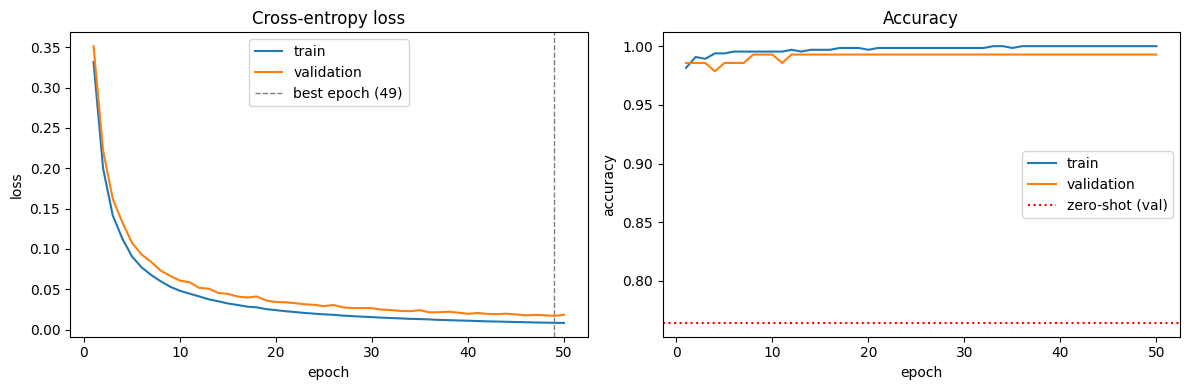

In [ ]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["train_loss"], label="train"); ax[0].plot(ep, history["val_loss"], label="validation")
ax[0].axvline(best_epoch, ls="--", c="grey", lw=1, label=f"best epoch ({best_epoch})")
ax[0].set(title="Cross-entropy loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
ax[1].plot(ep, history["train_acc"], label="train"); ax[1].plot(ep, history["val_acc"], label="validation")
ax[1].axhline(accuracy_score(y_val, zs_val_pred), ls=":", c="red", label="zero-shot (val)")
ax[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=120); plt.show()

## 7. AFTER — Zero-shot vs linear probe on the held-out **test** set

Zero-shot SigLIP      test accuracy: 0.7857
Frozen + linear probe test accuracy: 0.9929   (Δ = +20.7 pts)

=== Zero-shot ===
              precision    recall  f1-score   support

    Immature      0.684     1.000     0.812        65
      Mature      1.000     0.600     0.750        75

    accuracy                          0.786       140
   macro avg      0.842     0.800     0.781       140
weighted avg      0.853     0.786     0.779       140

=== Linear probe ===
              precision    recall  f1-score   support

    Immature      1.000     0.985     0.992        65
      Mature      0.987     1.000     0.993        75

    accuracy                          0.993       140
   macro avg      0.993     0.992     0.993       140
weighted avg      0.993     0.993     0.993       140



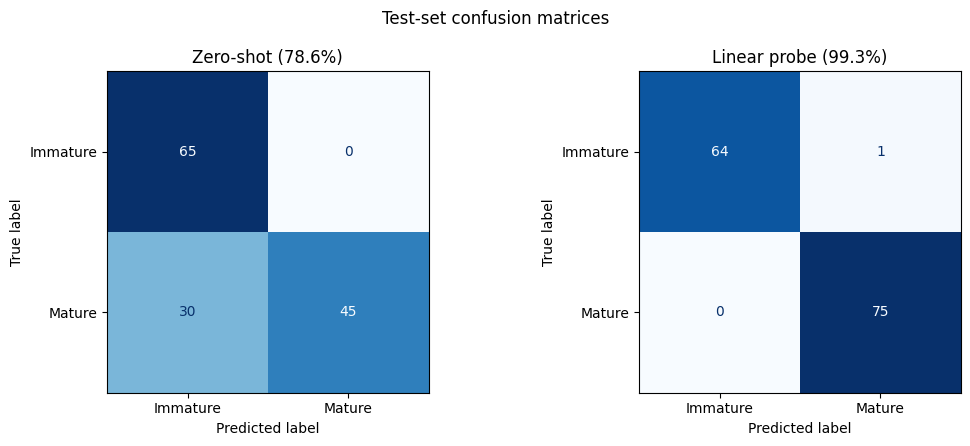

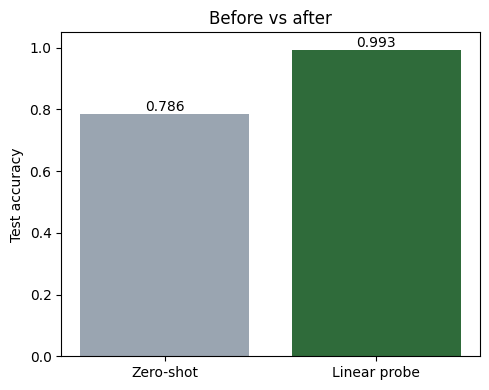

In [ ]:
with torch.no_grad():
    lp_test_pred = probe.head(X_test.to(device)).argmax(-1).cpu()

zs_acc, lp_acc = accuracy_score(y_test, zs_test_pred), accuracy_score(y_test, lp_test_pred)
print(f"Zero-shot SigLIP      test accuracy: {zs_acc:.4f}")
print(f"Frozen + linear probe test accuracy: {lp_acc:.4f}   (Δ = {100*(lp_acc-zs_acc):+.1f} pts)\n")

print("=== Zero-shot ===");    print(classification_report(y_test, zs_test_pred, target_names=CLASSES, digits=3))
print("=== Linear probe ==="); print(classification_report(y_test, lp_test_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, pred, title in [(ax[0], zs_test_pred, f"Zero-shot ({zs_acc:.1%})"), (ax[1], lp_test_pred, f"Linear probe ({lp_acc:.1%})")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASSES).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(title)
plt.suptitle("Test-set confusion matrices"); plt.tight_layout()
plt.savefig(OUT / "cm_test_comparison.png", dpi=120); plt.show()

plt.figure(figsize=(5, 4))
bars = plt.bar(["Zero-shot", "Linear probe"], [zs_acc, lp_acc], color=["#9aa5b1", "#2f6b3a"])
plt.bar_label(bars, fmt="%.3f"); plt.ylim(0, 1.05); plt.ylabel("Test accuracy"); plt.title("Before vs after")
plt.tight_layout(); plt.savefig(OUT / "accuracy_comparison.png", dpi=120); plt.show()

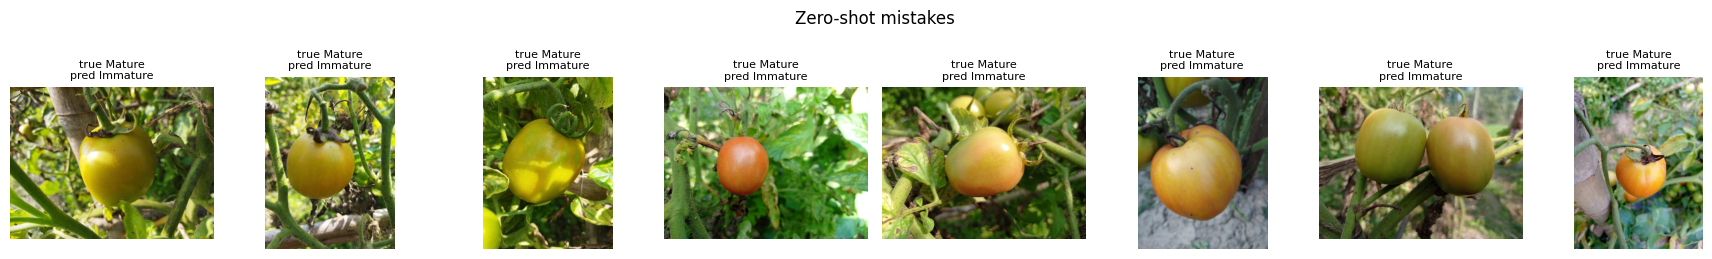

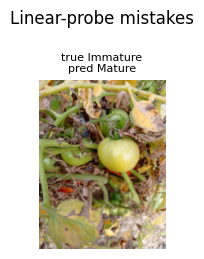

Zero-shot errors: 30 | Linear-probe errors: 1 of 140


In [ ]:
# Error analysis: which test images does each method get wrong?
def show_errors(pred, title, fname, k=8):
    wrong = np.where(pred.numpy() != y_test.numpy())[0][:k]
    if len(wrong) == 0: print(f"{title}: no errors 🎉"); return
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        a.imshow(Image.open(test_df.path.iloc[i]).convert("RGB"))
        a.set_title(f"true {CLASSES[y_test[i]]}\npred {CLASSES[pred[i]]}", fontsize=8); a.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(OUT / fname, dpi=120); plt.show()

show_errors(zs_test_pred, "Zero-shot mistakes", "errors_zero_shot.png")
show_errors(lp_test_pred, "Linear-probe mistakes", "errors_linear_probe.png")
print("Zero-shot errors:", int((zs_test_pred != y_test).sum()), "| Linear-probe errors:", int((lp_test_pred != y_test).sum()), "of", len(y_test))

## 8. Save results and the trained head

In [ ]:
torch.save(probe.head.state_dict(), OUT / "linear_head.pt")
results = {
    "model": MODEL_ID, "classes": CLASSES,
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "params_frozen": frozen, "params_trainable": trainable,
    "zero_shot_val_acc": accuracy_score(y_val, zs_val_pred),
    "zero_shot_test_acc": zs_acc, "linear_probe_test_acc": lp_acc,
    "zero_shot_report": classification_report(y_test, zs_test_pred, target_names=CLASSES, output_dict=True),
    "linear_probe_report": classification_report(y_test, lp_test_pred, target_names=CLASSES, output_dict=True),
    "cm_zero_shot_test": confusion_matrix(y_test, zs_test_pred).tolist(),
    "cm_linear_probe_test": confusion_matrix(y_test, lp_test_pred).tolist(),
    "final_train_loss": history["train_loss"][-1], "final_val_loss": history["val_loss"][-1],
    "best_epoch": best_epoch, "epochs": EPOCHS, "lr": LR, "batch_size": BS, "seed": SEED,
}
(OUT / "results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))

{
  "model": "google/siglip-base-patch16-224",
  "classes": [
    "Immature",
    "Mature"
  ],
  "n_train": 651,
  "n_val": 140,
  "n_test": 140,
  "params_frozen": 92884224,
  "params_trainable": 1538,
  "zero_shot_val_acc": 0.7642857142857142,
  "zero_shot_test_acc": 0.7857142857142857,
  "linear_probe_test_acc": 0.9928571428571429,
  "zero_shot_report": {
    "Immature": {
      "precision": 0.6842105263157895,
      "recall": 1.0,
      "f1-score": 0.8125,
      "support": 65.0
    },
    "Mature": {
      "precision": 1.0,
      "recall": 0.6,
      "f1-score": 0.75,
      "support": 75.0
    },
    "accuracy": 0.7857142857142857,
    "macro avg": {
      "precision": 0.8421052631578947,
      "recall": 0.8,
      "f1-score": 0.78125,
      "support": 140.0
    },
    "weighted avg": {
      "precision": 0.8533834586466166,
      "recall": 0.7857142857142857,
      "f1-score": 0.7790178571428571,
      "support": 140.0
    }
  },
  "linear_probe_report": {
    "Immature": {
     

## Conclusions

- Zero-shot SigLIP: **78.6%** test accuracy with no labelled data.
- Frozen backbone + 1,538-parameter linear head: **99.3%** test accuracy (**+20.7 pts**), training in seconds.
- Most remaining errors: 30 of 75.
- Limitations: small single-source dataset (931 unique original images after de-duplication, 651/140/140 split); binary task; no augmentation; single seed. With 140 test images, one image ≈ 0.7 pts, so 99.3% means one mistake, not a
  solved problem.



In [ ]:
!zip -r outputs.zip outputs
from google.colab import files
files.download("outputs.zip")


  adding: outputs/ (stored 0%)
  adding: outputs/errors_zero_shot.png (deflated 0%)
  adding: outputs/results.json (deflated 70%)
  adding: outputs/samples.png (deflated 0%)
  adding: outputs/cm_test_comparison.png (deflated 20%)
  adding: outputs/patch_grid.png (deflated 0%)
  adding: outputs/linear_head.pt (deflated 19%)
  adding: outputs/accuracy_comparison.png (deflated 19%)
  adding: outputs/training_curves.png (deflated 11%)
  adding: outputs/errors_linear_probe.png (deflated 1%)
  adding: outputs/cm_zero_shot_val.png (deflated 16%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
